# Mission EdStats : réduire le périmètre du dataset

Pour choisir les pays et les indicateurs cibles d'academy, il faut d'abord réduire le périmètre : `EdStatsCountry.csv` mélange des vrais pays et des agrégats (World, European Union...), et `EdStatsSeries.csv` compte des milliers d'indicateurs répartis en catégories. La réduction se fait en plusieurs étapes : les vrais pays (section 2), les catégories d'indicateurs retenues (section 3), les années gardées (section 4), où la complétude est mesurée (4.4) puis la réduction finale appliquée (4.5), puis le décompte des pays renseignés par indicateur et par année (section 5). Les CSV de sortie sont écrits dans `data/output/` (section 6).


### 1.1 Dossiers

Flux des données : `data/input/` contient les CSV bruts (lecture seule, jamais modifiés), `data/output/` reçoit les CSV réduits. Voir le `README.md` du projet.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pycountry
import shutil
from pathlib import Path

candidates = [
    Path.cwd() / "data" / "input",         # from the project root
    Path.cwd() / ".." / "data" / "input",  # from notebooks/
]

INPUT_DIR = None
for candidate in candidates:
    if candidate.exists():
        INPUT_DIR = candidate.resolve()
        break
if INPUT_DIR is None:
    raise FileNotFoundError("data/input/ not found")

OUTPUT_DIR = INPUT_DIR.parent / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_DIR, OUTPUT_DIR


(PosixPath('/Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/input'),
 PosixPath('/Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/output'))

### 1.2 Chargement brut

Défaut du fichier source : la virgule finale de chaque ligne crée une colonne vide « Unnamed », écartée à la lecture. Les accents des noms imposent l'encodage `utf-8`.

Source : les CSV de `data/input/` sont le jeu de données EdStats (Banque mondiale), téléchargé avec `make download` (voir `README.md` du projet).


In [2]:
def load_csv_input(name):
    """Read the CSV `name` from INPUT_DIR as is (raw)."""
    return pd.read_csv(
        INPUT_DIR / name,
        encoding="utf-8",
        usecols=lambda column: "Unnamed" not in column,
    )


## 2. Réduction aux vrais pays


### 2.1 Le référentiel

`EdStatsCountry.csv` : une ligne par pays ou agrégat, avec son `Country Code` (ex. `FRA`). Aperçu des 3 premières lignes :


In [3]:
# raw load kept for display only
dfs = {"EdStatsCountry.csv": load_csv_input("EdStatsCountry.csv")}
dfs["EdStatsCountry.csv"].head(3)


,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005


In [4]:
# separate load for computation
country = load_csv_input("EdStatsCountry.csv")
print(f"{country.shape[0]} rows, {country.shape[1]} columns")


241 rows, 31 columns


### 2.2 Le critère : un code ISO 3166-1 alpha-3 officiel

Critère retenu : un code ISO 3166-1 alpha-3 officiel (ex. `FRA`). Les agrégats de la Banque mondiale (World, European Union...) n'en ont pas.

Source : liste officielle ISO 3166-1 via `pycountry` (249 codes officiels, alpha-2 et alpha-3).


In [5]:
# all official ISO 3166-1 alpha-3 codes, as a plain list
iso_codes = []
for c in pycountry.countries:
    iso_codes.append(c.alpha_3)

# boolean filter: True when the row's Country Code is in that list
is_country = country["Country Code"].isin(iso_codes)

country_codes = country.loc[is_country, "Country Code"].tolist()  # the real countries
print(f"{len(country)} rows in the reference, {len(country_codes)} real countries kept")
print(", ".join(sorted(country_codes)))


241 rows in the reference, 214 real countries kept
ABW, AFG, AGO, ALB, AND, ARE, ARG, ARM, ASM, ATG, AUS, AUT, AZE, BDI, BEL, BEN, BFA, BGD, BGR, BHR, BHS, BIH, BLR, BLZ, BMU, BOL, BRA, BRB, BRN, BTN, BWA, CAF, CAN, CHE, CHL, CHN, CIV, CMR, COD, COG, COL, COM, CPV, CRI, CUB, CUW, CYM, CYP, CZE, DEU, DJI, DMA, DNK, DOM, DZA, ECU, EGY, ERI, ESP, EST, ETH, FIN, FJI, FRA, FRO, FSM, GAB, GBR, GEO, GHA, GIB, GIN, GMB, GNB, GNQ, GRC, GRD, GRL, GTM, GUM, GUY, HKG, HND, HRV, HTI, HUN, IDN, IMN, IND, IRL, IRN, IRQ, ISL, ISR, ITA, JAM, JOR, JPN, KAZ, KEN, KGZ, KHM, KIR, KNA, KOR, KWT, LAO, LBN, LBR, LBY, LCA, LIE, LKA, LSO, LTU, LUX, LVA, MAC, MAF, MAR, MCO, MDA, MDG, MDV, MEX, MHL, MKD, MLI, MLT, MMR, MNE, MNG, MNP, MOZ, MRT, MUS, MWI, MYS, NAM, NCL, NER, NGA, NIC, NLD, NOR, NPL, NRU, NZL, OMN, PAK, PAN, PER, PHL, PLW, PNG, POL, PRI, PRK, PRT, PRY, PSE, PYF, QAT, ROU, RUS, RWA, SAU, SDN, SEN, SGP, SLB, SLE, SLV, SMR, SOM, SRB, SSD, STP, SUR, SVK, SVN, SWE, SWZ, SXM, SYC, SYR, TCA, TCD, TGO, THA,

### 2.3 Les codes écartés

Les lignes écartées, avec leur nom et leur `Region` si renseignée :


In [6]:
excluded = country.loc[~is_country, ["Country Code", "Short Name", "Region"]]
print(f"{len(excluded)} codes excluded, {excluded['Region'].notna().sum()} of them with a Region:")
excluded


27 codes excluded, 2 of them with a Region:


,Country Code,Short Name,Region
5,ARB,Arab World,NaN
35,CHI,Channel Islands,Europe & Central Asia
57,EAP,East Asia & Pacific (developing only),NaN
58,EAS,East Asia & Pacific (all income levels),NaN
59,ECA,Europe & Central Asia (developing only),NaN
60,ECS,Europe & Central Asia (all income levels),NaN
63,EMU,Euro area,NaN
68,EUU,European Union,NaN
89,HIC,High income,NaN
92,HPC,Heavily indebted poor countries (HIPC),NaN


### 2.4 Deux codes écartés qui ont pourtant une région

`CHI` (Channel Islands) et `XKX` (Kosovo) ont une `Region` mais pas de code ISO officiel. Les deux critères diffèrent sur 4 codes, vus sur les données :


In [7]:
has_region = country["Region"].notna()
print(f"{len(country)} rows: Region set {has_region.sum()}, ISO code {is_country.sum()}, both {(has_region & is_country).sum()}")
print(f"Region yes / ISO no: {country.loc[has_region & ~is_country, 'Country Code'].tolist()}")
print(f"Region no / ISO yes: {country.loc[~has_region & is_country, 'Country Code'].tolist()}")
print(f"neither: {(~has_region & ~is_country).sum()} rows")


241 rows: Region set 214, ISO code 214, both 212
Region yes / ISO no: ['CHI', 'XKX']
Region no / ISO yes: ['GIB', 'NRU']
neither: 25 rows


Ces noms ont-ils un code ISO officiel sous une autre forme ? Vérification dans la liste officielle :


In [8]:
# name -> alpha-3 code for the whole official ISO list
iso_by_name = {}
for c in pycountry.countries:
    iso_by_name[c.name] = c.alpha_3

for name in ["Channel Islands", "Kosovo", "Jersey", "Guernsey"]:
    print(f"{name}: {iso_by_name.get(name, 'not in the official ISO list')}")  # .get(key, default) returns the default if the key is missing


Channel Islands: not in the official ISO list
Kosovo: not in the official ISO list
Jersey: JEY
Guernsey: GGY


Sources externes (liens ci-dessous) : le Kosovo est un État au statut contesté, « Code ISO 3166-1 : aucun », le code `XK` n'étant « à usage personnel » (Wikipédia, « Kosovo ») ; les îles Anglo-Normandes forment deux États, Jersey et Guernesey (Wikipédia, « Îles Anglo-Normandes »), chacun avec son code ISO officiel (`JEY`, `GGY` ci-dessus). `CHI` est donc un agrégat, `XKX` n'a pas de code officiel : le critère ISO les écarte à raison.

- Wikipédia, « Kosovo » : https://fr.wikipedia.org/wiki/Kosovo
- Wikipédia, « Îles Anglo-Normandes » : https://fr.wikipedia.org/wiki/Îles_Anglo-Normandes


### 2.5 Nettoyage du référentiel

Décision : le référentiel nettoyé est écrit dans `data/output/` (section 6) ; `data/input/` reste en lecture seule.


Bilan : lignes avant / après, puis codes écartés.


In [9]:
# boolean filter on the column, no iloc: keep only the real countries
country_cleaned = country[country["Country Code"].isin(country_codes)]

excluded_codes = sorted(set(country["Country Code"]) - set(country_codes))
print(f"{len(country)} rows in the input, {len(country_cleaned)} rows kept")
print(f"{len(excluded_codes)} codes excluded: {', '.join(excluded_codes)}")

241 rows in the input, 214 rows kept
27 codes excluded: ARB, CHI, EAP, EAS, ECA, ECS, EMU, EUU, HIC, HPC, LAC, LCN, LDC, LIC, LMC, LMY, MEA, MIC, MNA, NAC, OED, SAS, SSA, SSF, UMC, WLD, XKX


Aperçu des 3 premières lignes du référentiel nettoyé :

In [10]:
country_cleaned.head(3)

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005


### 2.6 Propagation aux autres fichiers

Trois autres fichiers de `data/input/` portent une clé pays : `EdStatsData.csv` (colonne `Country Code`), `EdStatsFootNote.csv` et `EdStatsCountry-Series.csv` (colonne `CountryCode`). Le même filtre leur est appliqué, avec un bilan lignes avant / après par fichier ; l'écriture des CSV se fait en section 6.


`EdStatsData.csv` : une ligne par pays et par indicateur, la clé pays est dans `Country Code`.

In [11]:
# the country key of EdStatsData.csv is in the "Country Code" column
data = load_csv_input("EdStatsData.csv")
data_cleaned = data[data["Country Code"].isin(country_codes)]
print(f"EdStatsData.csv: {len(data)} rows in the input, {len(data_cleaned)} rows kept")

EdStatsData.csv: 886930 rows in the input, 784310 rows kept


`EdStatsFootNote.csv` : une ligne par pays, indicateur et année, la clé pays est dans `CountryCode`.

In [12]:
# the country key of EdStatsFootNote.csv is in the "CountryCode" column
footnote = load_csv_input("EdStatsFootNote.csv")
footnote_cleaned = footnote[footnote["CountryCode"].isin(country_codes)]
print(f"EdStatsFootNote.csv: {len(footnote)} rows in the input, {len(footnote_cleaned)} rows kept")

EdStatsFootNote.csv: 643638 rows in the input, 517413 rows kept


`EdStatsCountry-Series.csv` : une ligne par couple pays × indicateur, la clé pays est dans `CountryCode`.

In [13]:
# the country key of EdStatsCountry-Series.csv is in the "CountryCode" column
country_series = load_csv_input("EdStatsCountry-Series.csv")
country_series_cleaned = country_series[country_series["CountryCode"].isin(country_codes)]
print(f"EdStatsCountry-Series.csv: {len(country_series)} rows in the input, {len(country_series_cleaned)} rows kept")

EdStatsCountry-Series.csv: 613 rows in the input, 599 rows kept


`EdStatsSeries.csv` est le dictionnaire des indicateurs : une ligne par indicateur (`Series Code`), aucune clé pays. Il n'est donc pas filtré ici et arrive tel quel dans `data/output/` (section 6). Preuve sur l'en-tête du fichier :


In [14]:
# read only the header line to list the columns of EdStatsSeries.csv
series_header = pd.read_csv(INPUT_DIR / "EdStatsSeries.csv", encoding="utf-8", nrows=0)
country_columns = [c for c in series_header.columns if "country" in c.lower()]
print(f"{len(series_header.columns)} columns, {len(country_columns)} with a country key: {country_columns}")

21 columns, 0 with a country key: []


### Bilan

214 vrais pays retenus dans `country_codes` sur les 241 lignes du référentiel, 27 écartés (agrégats + `CHI`/`XKX`, section 2.4). Le même filtre a été propagé aux trois autres fichiers qui portent une clé pays (section 2.6, bilans lignes avant / après en sortie de code). Les résultats filtrés sont écrits dans `data/output/` en section 6. Prochaine étape : choisir les catégories d'indicateurs pertinentes (section 3 ci-dessous).

## 3. Les catégories d'indicateurs

Deuxième volet de la réduction : choisir les indicateurs. `EdStatsSeries.csv` est le référentiel des indicateurs : une ligne par indicateur, avec son code (`Series Code`), son nom (`Indicator Name`) et sa catégorie (`Topic`).


### 3.1 Le référentiel des indicateurs

Parmi les jeux de données centrés sur les indicateurs (`EdStatsData.csv`, `EdStatsSeries.csv`, `EdStatsCountry-Series.csv`, `EdStatsFootNote.csv`), lequel porte la catégorie métier de chaque indicateur ?

Aperçu des 3 premières lignes du dictionnaire des indicateurs, sur les colonnes utiles :

In [15]:
# raw load kept for display only
dfs["EdStatsSeries.csv"] = load_csv_input("EdStatsSeries.csv")
dfs["EdStatsSeries.csv"][["Series Code", "Topic", "Indicator Name"]].head(3)


,Series Code,Topic,Indicator Name
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 ...
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...


In [16]:
# separate load for computation
series = load_csv_input("EdStatsSeries.csv")
print(f"{series.shape[0]} indicators, {series.shape[1]} columns")
print(f"{series['Topic'].nunique()} categories in the Topic column")


3665 indicators, 20 columns
37 categories in the Topic column


### 3.2 La colonne de catégorie métier

Les colonnes de chaque jeu centré sur les indicateurs, lues sur l'en-tête seule :


In [17]:
# header only (nrows=0): the columns of each indicator-centered file
indicator_files = ["EdStatsData.csv", "EdStatsSeries.csv", "EdStatsCountry-Series.csv", "EdStatsFootNote.csv"]
file_columns = {}
for name in indicator_files:
    header = pd.read_csv(
        INPUT_DIR / name,
        encoding="utf-8",
        nrows=0,
        usecols=lambda column: "Unnamed" not in column,  # trailing comma in the CSV creates an empty column
    )
    file_columns[name] = header.columns.tolist()

In [18]:
pd.DataFrame({
    "Fichier": indicator_files,
    "Colonnes": [", ".join(file_columns[name]) for name in indicator_files],
})

,Fichier,Colonnes
0,EdStatsData.csv,"Country Name, Country Code, Indicator Name, In..."
1,EdStatsSeries.csv,"Series Code, Topic, Indicator Name, Short defi..."
2,EdStatsCountry-Series.csv,"CountryCode, SeriesCode, DESCRIPTION"
3,EdStatsFootNote.csv,"CountryCode, SeriesCode, Year, DESCRIPTION"


In [19]:
# a category column: the one whose name contains "topic"
category_column = {}
for name in indicator_files:
    for col in file_columns[name]:
        if "topic" in col.lower():
            category_column[name] = col

In [20]:
print(f"Category column: {category_column}")  # only one file has one

Category column: {'EdStatsSeries.csv': 'Topic'}


### 3.3 Toutes les catégories présentes

`Topic` dans `EdStatsSeries.csv` est la colonne de catégorie métier. Nombre d'indicateurs par catégorie, de la plus fournie à la moins fournie :


In [21]:
# raw count of indicators per category, most frequent first
topic_counts = series["Topic"].value_counts()

In [22]:
topic_counts

Topic
Learning Outcomes                                                                               1046
Attainment                                                                                       733
Education Equality                                                                               426
Secondary                                                                                        256
Primary                                                                                          248
Population                                                                                       213
Tertiary                                                                                         158
Teachers                                                                                         137
Expenditures                                                                                      93
Engaging the Private Sector (SABER)                                                  

### 3.4 Liste des catégories, traduites en français

Chaque catégorie (`Topic`) avec son nombre d'indicateurs et sa traduction en français, de la plus fournie à la moins fournie. Les traductions suivent la terminologie française de la Banque mondiale (portail EdStats et sa version française : donnees.banquemondiale.org, blogs et rapports SABER en français). « Laber » est une coquille du fichier source pour « Labor » (emploi).

Source : portail EdStats, https://datatopics.worldbank.org/education/ (thèmes Learning Outcomes, Attainment, Equity, Expenditures, Policy, EMIS) et sa version française.


In [23]:
# one row per category, most indicators first
topics = series["Topic"].value_counts().rename_axis("Topic").reset_index(name="indicators")

# English topic -> French label, following the World Bank's French terminology
topic_fr = {
    "Learning Outcomes": "Acquis scolaires",
    "Attainment": "Niveau d'éducation",
    "Education Equality": "Égalité dans l'éducation",
    "Secondary": "Enseignement secondaire",
    "Primary": "Enseignement primaire",
    "Population": "Population",
    "Tertiary": "Enseignement supérieur",
    "Teachers": "Enseignants",
    "Expenditures": "Dépenses",
    "Engaging the Private Sector (SABER)": "Participation du secteur privé (SABER)",
    "Literacy": "Alphabétisation",
    "School Autonomy and Accountability (SABER)": "Autonomie et redevabilité des établissements scolaires (SABER)",
    "Teachers (SABER)": "Enseignants (SABER)",
    "Early Childhood Education": "Éducation de la petite enfance",
    "Education Management Information Systems (SABER)": "Systèmes de gestion de l'information dans l'éducation (SABER)",
    "Post-Secondary/Non-Tertiary": "Enseignement post-secondaire non supérieur",
    "School Finance (SABER)": "Financement des écoles (SABER)",
    "Tertiary Education (SABER)": "Enseignement supérieur (SABER)",
    "Student Assessment (SABER)": "Évaluation des élèves (SABER)",
    "Pre-Primary": "Éducation préprimaire",
    "Health: Population: Structure": "Santé : population : structure",
    "Early Child Development (SABER)": "Développement de la petite enfance (SABER)",
    "Workforce Development (SABER)": "Développement de la main-d'œuvre (SABER)",
    "Social Protection & Labor: Labor force structure": "Protection sociale et emploi : structure de la main-d'œuvre",
    "School Health and School Feeding (SABER)": "Santé scolaire et alimentation scolaire (SABER)",
    "Economic Policy & Debt: Purchasing power parity": "Politique économique et dette : parité de pouvoir d'achat",
    "Economic Policy & Debt: National accounts: US$ at current prices: Aggregate indicators": "Politique économique et dette : comptes nationaux : $US aux prix courants : indicateurs agrégés",
    "Laber": "Emploi",
    "Social Protection & Labor: Unemployment": "Protection sociale et emploi : chômage",
    "Infrastructure: Communications": "Infrastructure : communications",
    "Economic Policy & Debt: National accounts: US$ at constant 2010 prices: Aggregate indicators": "Politique économique et dette : comptes nationaux : $US aux prix constants de 2010 : indicateurs agrégés",
    "Background": "Contexte",
    "EMIS": "Systèmes de gestion de l'information dans l'éducation (EMIS)",
    "Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita": "Politique économique et dette : comptes nationaux : RNB méthode Atlas et RNB par habitant",
    "Health: Risk factors": "Santé : facteurs de risque",
    "Health: Mortality": "Santé : mortalité",
    "Health: Population: Dynamics": "Santé : population : dynamique",
}

# map() looks up each English topic in the dict and adds the French label
topics["Catégorie (FR)"] = topics["Topic"].map(topic_fr)
print(f"{topics['Catégorie (FR)'].isna().sum()} catégories sans traduction sur {len(topics)}")


0 catégories sans traduction sur 37


In [24]:
# the table: French label first, then the original English topic and the count
topics[["Catégorie (FR)", "Topic", "indicators"]]


,Catégorie (FR),Topic,indicators
0,Acquis scolaires,Learning Outcomes,1046
1,Niveau d'éducation,Attainment,733
2,Égalité dans l'éducation,Education Equality,426
3,Enseignement secondaire,Secondary,256
4,Enseignement primaire,Primary,248
5,Population,Population,213
6,Enseignement supérieur,Tertiary,158
7,Enseignants,Teachers,137
8,Dépenses,Expenditures,93
9,Participation du secteur privé (SABER),Engaging the Private Sector (SABER),51


### 3.5 Choisir les catégories pertinentes

Objectif de Mark : quels pays cibler pour les cours en ligne d'academy (lycée et université), et comment ce potentiel évolue. Une catégorie se garde si elle répond à une question concrète sur le pays (traduction entre parenthèses, comme dans le tableau 3.4) :

- **taille du marché** (combien de jeunes, aujourd'hui et demain) : `Population`, avec projections 2100
- **niveau des élèves** : `Attainment` (niveau d'éducation), `Literacy` (alphabétisation des 15-24 ans), `Learning Outcomes` (acquis scolaires)
- **taille du lycée et de l'université** : `Secondary` (enseignement secondaire), `Tertiary` (enseignement supérieur)
- **système éducatif actif et financé** : `Teachers` (enseignants), `Expenditures` (dépenses)
- **clients capables de payer et de se connecter** : `Economic Policy & Debt` (politique économique et dette : PIB par habitant, PPP), `Infrastructure: Communications` (infrastructure : communications, ex. `Internet users (per 100 people)`)

**Pourquoi écarter les SABER** (diagnostics de politique éducative de la Banque mondiale) ? Preuve dans le fichier : ce sont des notes de 1 à 4 (« 1=Latent … 4=Advanced ») sur le cadre politique du système éducatif, une valeur par pays. Elles ne disent ni le nombre d'élèves, ni leur niveau, ni leur pouvoir d'achat. Source : page SABER de la Banque mondiale, https://www.worldbank.org/en/brief/2021/06/23/systems-approach-for-better-education-results-saber.

Écartés aussi : `Pre-Primary` (éducation préprimaire), `Early Childhood Education` (éducation de la petite enfance), `Primary` (enseignement primaire), `Post-Secondary/Non-Tertiary` (post-secondaire non supérieur), soit des niveaux hors du public d'academy ; `Education Equality` (égalité dans l'éducation, écarts internes à un pays) ; et les sujets hors marché : santé, emploi, `EMIS` (systèmes de gestion de l'information), `Background` (contexte).

Hypothèses documentées : le choix des catégories gardées est explicite et facile à modifier.

In [25]:
# SABER proof from the file itself: one source, an ordinal rating scale
saber = series[series["Topic"].str.contains("SABER")]
print(f"{len(saber)} indicateurs SABER, source : {saber['Source'].unique()[0]}")
print(f"échelle de notation : {saber['Short definition'].iloc[0][:70]}")

215 indicateurs SABER, source : Systems Approach for Better Education Results (SABER), World Bank
échelle de notation : Data Interpretation: 1=Latent; 2=Emerging; 3=Established; 4=Advanced. 


In [26]:
# the categories we keep: edit this list to change the selection
kept_topics = [
    "Population",
    "Learning Outcomes",
    "Attainment",
    "Literacy",
    "Secondary",
    "Tertiary",
    "Teachers",
    "Expenditures",
    "Infrastructure: Communications",
    "Economic Policy & Debt: Purchasing power parity",
    "Economic Policy & Debt: National accounts: US$ at current prices: Aggregate indicators",
    "Economic Policy & Debt: National accounts: US$ at constant 2010 prices: Aggregate indicators",
    "Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita",
]

# boolean filter on the Topic column: only the kept categories
kept_series = series[series["Topic"].isin(kept_topics)]
remaining = len(kept_series)  # number of remaining indicators

# one row per kept category, most indicators first, with the French label
kept_counts = kept_series["Topic"].value_counts().rename_axis("Topic").reset_index(name="indicators")
kept_counts["Catégorie (FR)"] = kept_counts["Topic"].map(topic_fr)

In [27]:
# display only: the total, then one row per kept category
print(f"{remaining} indicateurs restants sur {len(series)} ({len(kept_topics)} catégories gardées sur {series['Topic'].nunique()})")
kept_counts[["Catégorie (FR)", "Topic", "indicators"]]

2682 indicateurs restants sur 3665 (13 catégories gardées sur 37)


,Catégorie (FR),Topic,indicators
0,Acquis scolaires,Learning Outcomes,1046
1,Niveau d'éducation,Attainment,733
2,Enseignement secondaire,Secondary,256
3,Population,Population,213
4,Enseignement supérieur,Tertiary,158
5,Enseignants,Teachers,137
6,Dépenses,Expenditures,93
7,Alphabétisation,Literacy,32
8,Politique économique et dette : parité de pouv...,Economic Policy & Debt: Purchasing power parity,6
9,Politique économique et dette : comptes nation...,Economic Policy & Debt: National accounts: US$...,3


### 3.6 Propager le filtre aux indicateurs retenus

Quatre fichiers portent une clé indicateur : `EdStatsData.csv` (colonne `Indicator Code`), `EdStatsFootNote.csv` et `EdStatsCountry-Series.csv` (colonne `SeriesCode`), `EdStatsSeries.csv` (colonne `Series Code`). `EdStatsCountry.csv` n'a pas de clé indicateur : il n'est pas concerné. Bilan lignes avant / après par fichier ; l'écriture se fait en section 6.


In [28]:
# the Series Codes of the kept indicators: the filter list for every indicator key
selected_codes = kept_series["Series Code"].tolist()
print(f"{len(selected_codes)} selected indicator codes")

2682 selected indicator codes


`EdStatsData.csv` : une ligne par pays et par indicateur, la clé indicateur est dans `Indicator Code`.

In [29]:
# the indicator key of EdStatsData.csv is in the "Indicator Code" column
rows_before = len(data_cleaned)
data_cleaned = data_cleaned[data_cleaned["Indicator Code"].isin(selected_codes)]
print(f"EdStatsData.csv: {rows_before} rows after the country filter, {len(data_cleaned)} rows kept")

EdStatsData.csv: 784310 rows after the country filter, 566030 rows kept


`EdStatsFootNote.csv` : une ligne par pays, indicateur et année, la clé indicateur est dans `SeriesCode`.

In [30]:
# the indicator key of EdStatsFootNote.csv is in the "SeriesCode" column
rows_before = len(footnote_cleaned)
footnote_cleaned = footnote_cleaned[footnote_cleaned["SeriesCode"].isin(selected_codes)]
print(f"EdStatsFootNote.csv: {rows_before} rows after the country filter, {len(footnote_cleaned)} rows kept")

EdStatsFootNote.csv: 517413 rows after the country filter, 294829 rows kept


`EdStatsCountry-Series.csv` : une ligne par couple pays × indicateur, la clé indicateur est dans `SeriesCode`.

In [31]:
# the indicator key of EdStatsCountry-Series.csv is in the "SeriesCode" column
rows_before = len(country_series_cleaned)
country_series_cleaned = country_series_cleaned[country_series_cleaned["SeriesCode"].isin(selected_codes)]
print(f"EdStatsCountry-Series.csv: {rows_before} rows after the country filter, {len(country_series_cleaned)} rows kept")

EdStatsCountry-Series.csv: 599 rows after the country filter, 109 rows kept


`EdStatsSeries.csv` : le dictionnaire des indicateurs, une ligne par indicateur, la clé est dans `Series Code`. Contrairement au filtre pays, le filtre indicateurs s'y applique.

In [32]:
# the indicator key of EdStatsSeries.csv is in the "Series Code" column
rows_before = len(series)
series_cleaned = series[series["Series Code"].isin(selected_codes)]
print(f"EdStatsSeries.csv: {rows_before} rows in the input, {len(series_cleaned)} rows kept")

EdStatsSeries.csv: 3665 rows in the input, 2682 rows kept


`EdStatsCountry.csv` n'a pas de clé indicateur : aucune ligne n'est retirée par ce filtre. Preuve sur l'en-tête du fichier :


In [33]:
# read only the header line: EdStatsCountry.csv has no indicator column
country_header = pd.read_csv(INPUT_DIR / "EdStatsCountry.csv", encoding="utf-8", nrows=0)
indicator_columns = [c for c in country_header.columns if "indicator" in c.lower() or "series" in c.lower()]
print(f"{len(country_header.columns)} columns, {len(indicator_columns)} with an indicator key: {indicator_columns}")

32 columns, 0 with an indicator key: []


### Bilan

13 catégories gardées sur 37 : 2 682 indicateurs retenus sur 3 665. Le filtre a été propagé aux quatre fichiers qui portent une clé indicateur, avec un bilan lignes avant / après pour chacun (sorties de code ci-dessus). `EdStatsCountry.csv` n'est pas concerné. Les résultats sont écrits dans `data/output/` en section 6, avec le référentiel pays nettoyé.

## 4. Les années d'`EdStatsData.csv` : filtrer, puis mesurer leur complétude

`EdStatsData.csv` a une colonne par année : des mesures de 1970 à 2017, puis des projections tous les 5 ans de 2020 à 2100 (tendances calculées par la Banque mondiale, pas des mesures ; voir `data_overview.ipynb`). Le dataset date de 2016 : on se place en 2016.

### 4.1 Les colonnes d'années

4 colonnes identifient chaque ligne (`Country Name`, `Country Code`, `Indicator Name`, `Indicator Code`) ; toutes les suivantes sont des années :

In [34]:
# the year columns: every column after the 4 identification columns
year_columns = data_cleaned.columns[4:]
annual = [c for c in year_columns if int(c) <= 2017]
proj = [c for c in year_columns if int(c) >= 2020]

print(f"{len(year_columns)} year columns: {len(annual)} annual ({annual[0]} to {annual[-1]}), "
      f"{len(proj)} projections every 5 years ({proj[0]} to {proj[-1]})")


65 year columns: 48 annual (1970 to 2017), 17 projections every 5 years (2020 to 2100)


### 4.2 Supprimer les années avant 2000

On garde les mesures 2000-2017 et les projections 2020-2100. Les années 1970-1999 sont supprimées : pré-internet, hors périmètre. Le bilan avant/après prouve le filtre.

In [35]:
# the years to drop: before 2000 (pre-internet, outside the business perimeter)
years_to_drop = np.arange(1970, 2000)  # 1970 to 1999
years_to_drop = [str(year) for year in years_to_drop]  # the column names are strings

# boolean filter on the column names with isin(): keep the columns not in the drop list
columns_before = len(data_cleaned.columns)
data_cleaned = data_cleaned.loc[:, ~data_cleaned.columns.isin(years_to_drop)]

print(f"{columns_before} columns before, {len(data_cleaned.columns)} after: "
      f"{columns_before - len(data_cleaned.columns)} year columns dropped")


69 columns before, 39 after: 30 year columns dropped


### 4.3 Les années retenues

Après le filtre, il reste :

In [36]:
# the year columns kept after the filter
kept_year_columns = data_cleaned.columns[4:]
annual = [c for c in kept_year_columns if int(c) <= 2017]
proj = [c for c in kept_year_columns if int(c) >= 2020]

print(f"{len(kept_year_columns)} year columns kept: {len(annual)} annual ({annual[0]} to {annual[-1]}), "
      f"{len(proj)} projections every 5 years ({proj[0]} to {proj[-1]})")


35 year columns kept: 18 annual (2000 to 2017), 17 projections every 5 years (2020 to 2100)


### 4.4 Mesurer la complétude

`data_cleaned` contient 214 pays, 2 645 indicateurs et 35 colonnes d'années. On mesure la proportion de valeurs renseignées (non manquantes), avec une seule fonction pour deux vues : par année et par indicateur. Ces résultats serviront à choisir quelles années et quels indicateurs garder.

#### 4.4.1 Une fonction pour les deux mesures

`melt()` passe en format long : une ligne par indicateur × année, avec la colonne `value` (NaN = vide). `proportion_remplie()` (taux de remplissage, fill rate) groupe par la colonne choisie (`year` ou `Indicator Code`) et calcule la moyenne de `notna()` : True = renseignée, donc la moyenne = la proportion renseignée.

In [37]:
# long format: one row per country x indicator x year, value = the cell (NaN when missing)
# kept_year_columns was set in 4.3: the year columns kept after the filter of 4.2
data_long = data_cleaned.melt(
    id_vars=["Indicator Code"],
    value_vars=kept_year_columns,
    var_name="year",
    value_name="value",
)
print(f"{len(data_long)} rows = {len(data_cleaned)} rows x {len(kept_year_columns)} year columns")

19811050 rows = 566030 rows x 35 year columns


In [38]:
def proportion_remplie(data_long, group_column):
    """Share of filled (non-missing) values, grouped by group_column ('year' or 'Indicator Code')."""
    is_filled = data_long["value"].notna()  # True when the cell has a value
    return data_long.assign(is_filled=is_filled).groupby(group_column)["is_filled"].mean()

#### 4.4.2 Par année : proportion d'indicateurs renseignés

`proportion_indicateurs_par_annee` : pour chaque année, la part de lignes (pays × indicateur) renseignées. Sur le graphique : bleu = mesures 2000-2017, orange = projections 2020-2100.

In [39]:
# calculation: group by year
proportion_indicateurs_par_annee = proportion_remplie(data_long, "year")

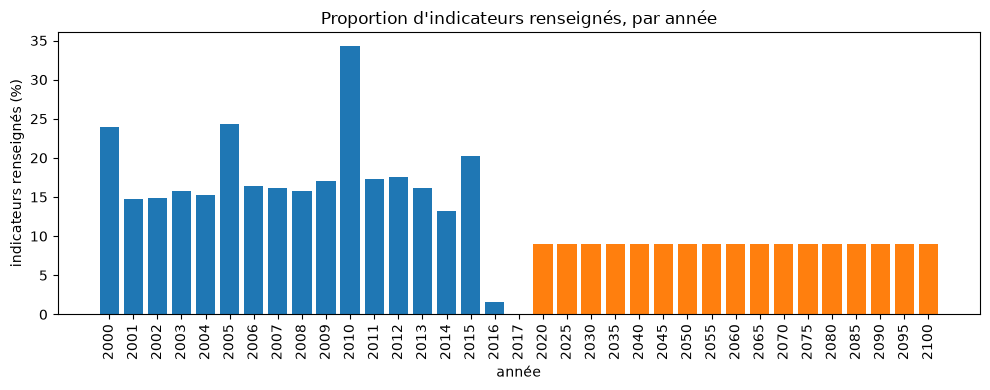

In [40]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = ["tab:blue" if int(year) <= 2017 else "tab:orange" for year in proportion_indicateurs_par_annee.index]
ax.bar(proportion_indicateurs_par_annee.index, proportion_indicateurs_par_annee.values * 100, color=colors)
ax.set_xlabel("année")
ax.set_ylabel("indicateurs renseignés (%)")
ax.set_title("Proportion d'indicateurs renseignés, par année")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Lecture** : les mesures (bleu) vont de 13 % à 34 % de remplissage, avec un pic en 2010 ; 2016 (2 %) et 2017 (0 %) s'effondrent ; les projections (orange) sont toutes à ~9 %. Plus la barre est haute, plus l'année est fiable : 2016-2017 sont quasi vides, donc inexploitables ; les ~9 % constants des projections viennent du modèle de projection, pas de vraies mesures.

#### 4.4.3 Par indicateur : proportion d'années renseignées

`proportion_annees_par_indicateur` : pour chaque indicateur, la part de ses 35 années renseignées. Le boxplot en résume la distribution, puis le top 15 liste les indicateurs les plus complets.

In [41]:
# calculation: group by indicator
proportion_annees_par_indicateur = proportion_remplie(data_long, "Indicator Code")
print(f"{len(proportion_annees_par_indicateur)} indicateurs")
proportion_annees_par_indicateur.describe().round(3)

2645 indicateurs


count    2645.000
mean        0.128
std         0.158
min         0.000
25%         0.003
50%         0.058
75%         0.225
max         0.459
Name: is_filled, dtype: float64

**Boîte à moustache (boxplot)** : la boîte va de Q1 à Q3 (moitié centrale des indicateurs), le trait est la médiane, les moustaches jusqu'aux extrêmes (au-delà de 1,5 × IQR : outliers). Ici : médiane ~6 %, Q3 ~22 %, max ~46 %.

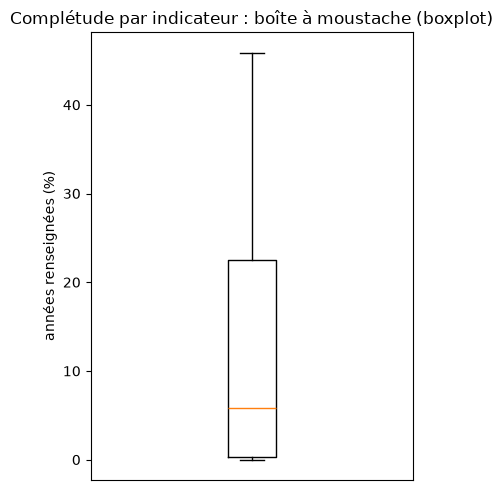

In [42]:
fig, ax = plt.subplots(figsize=(4, 5))
ax.boxplot(proportion_annees_par_indicateur.values * 100, orientation="vertical")  # vertical box, the usual way
ax.set_ylabel("années renseignées (%)")
ax.set_xticks([])  # no x axis: a single box
ax.set_title("Complétude par indicateur : boîte à moustache (boxplot)")
plt.tight_layout()
plt.show()

**Lecture** : l'axe vertical donne, pour chaque indicateur, le % de ses 35 années renseignées. La médiane (~6 %) : la moitié des indicateurs est en dessous. La boîte va de Q1 (~0 %) à Q3 (~22 %). La moustache haute monte jusqu'au maximum (~46 %) : c'est l'indicateur le plus complet, sans outlier au-delà. Autrement dit, plus un indicateur est haut, plus il est complet, et très peu dépassent 40 %. Ce sont eux, en haut, que la réduction gardera.

Les 15 indicateurs les plus complets, avec leur nom :

In [43]:
# calculation: top 15 most complete indicators, joined with their names
indicator_names = data_cleaned.drop_duplicates("Indicator Code").set_index("Indicator Code")["Indicator Name"]
top_indicateurs = proportion_annees_par_indicateur.sort_values(ascending=False).head(15)
top_table = pd.DataFrame({
    "Indicator Code": top_indicateurs.index,
    "proportion d'années renseignées": top_indicateurs.values.round(3),
    "Indicator Name": indicator_names.reindex(top_indicateurs.index).values,
})

In [44]:
# display only
top_table

,Indicator Code,proportion d'années renseignées,Indicator Name
0,SE.SEC.DURS.UP,0.459,Theoretical duration of upper secondary educat...
1,SE.SEC.DURS,0.459,Theoretical duration of secondary education (y...
2,SE.SEC.AGES,0.459,Official entrance age to lower secondary educa...
3,IT.NET.USER.P2,0.454,Internet users (per 100 people)
4,NY.GDP.PCAP.CD,0.452,GDP per capita (current US$)
5,NY.GDP.MKTP.CD,0.452,GDP at market prices (current US$)
6,NY.GDP.PCAP.KD,0.443,GDP per capita (constant 2005 US$)
7,NY.GDP.MKTP.KD,0.443,GDP at market prices (constant 2005 US$)
8,SP.SEC.UTOT.MA.IN,0.435,Population of the official age for upper secon...
9,SP.SEC.UTOT.IN,0.435,Population of the official age for upper secon...


#### 4.4.4 Conclusion : seuil retenu pour les indicateurs

Décision : on garde les indicateurs au-dessus de Q3 = 22,5 % d'années renseignées, soit 662 indicateurs sur 2 645 (le quart le plus complet). Repères : médiane ~6 % (la plupart sont peu remplis), max ~46 % (le plus complet).

Côté années : 2016 (2 %) et 2017 (0 %) sont inexploitables. Ces seuils sont appliqués en 4.5 ; les CSV de `data/output/` sont réécrits en section 6.

### 4.5 Appliquer la réduction retenue

Seuils retenus en 4.4.4 : indicateurs à taux de remplissage ≥ Q3 (22,5 %) ; années 2016 et 2017 supprimées, projections 2020-2100 gardées. On applique à `data_cleaned`, on propage aux fichiers à clé indicateur ; la section 6 réécrit les CSV de `data/output/`.

#### 4.5.1 Les indicateurs retenus (seuil Q3)

Q3 se calcule sur `proportion_annees_par_indicateur` ; on garde les indicateurs au-dessus :

In [45]:
# the retained indicators: fill rate >= Q3
q3 = proportion_annees_par_indicateur.quantile(0.75)
kept_indicator_codes = proportion_annees_par_indicateur[
    proportion_annees_par_indicateur >= q3
].index.tolist()
print(f"seuil Q3 = {q3:.1%} -> {len(kept_indicator_codes)} indicateurs retenus sur {len(proportion_annees_par_indicateur)}")

seuil Q3 = 22.5% -> 662 indicateurs retenus sur 2645


#### 4.5.2 Filtrer `data_cleaned` sur ces indicateurs

Même filtre qu'en 3.6, avec la nouvelle liste :

In [46]:
# indicator filter on EdStatsData.csv: keep only the retained indicators
rows_before = len(data_cleaned)
data_cleaned = data_cleaned[data_cleaned["Indicator Code"].isin(kept_indicator_codes)]
print(f"EdStatsData.csv: {rows_before} rows before, {len(data_cleaned)} rows kept")

EdStatsData.csv: 566030 rows before, 141668 rows kept


#### 4.5.3 Supprimer les colonnes 2016 et 2017

Leurs taux de remplissage sont de 2 % et 0 % (4.4.2) : inexploitables. Les projections 2020-2100 restent.

In [47]:
# drop the year columns 2016 and 2017 (fill rate 2% and 0%), keep the projections
columns_before = len(data_cleaned.columns)
data_cleaned = data_cleaned.loc[:, ~data_cleaned.columns.isin(["2016", "2017"])]
print(f"{columns_before} columns before, {len(data_cleaned.columns)} after: 2016 and 2017 dropped")

39 columns before, 37 after: 2016 and 2017 dropped


#### 4.5.4 Propager le filtre aux autres fichiers à clé indicateur

`EdStatsFootNote.csv` et `EdStatsCountry-Series.csv` (colonne `SeriesCode`), `EdStatsSeries.csv` (colonne `Series Code`) :

In [48]:
# propagate the completeness filter to every file with an indicator key
rows_before = len(footnote_cleaned)
footnote_cleaned = footnote_cleaned[footnote_cleaned["SeriesCode"].isin(kept_indicator_codes)]
print(f"EdStatsFootNote.csv: {rows_before} rows before, {len(footnote_cleaned)} rows kept")

rows_before = len(country_series_cleaned)
country_series_cleaned = country_series_cleaned[country_series_cleaned["SeriesCode"].isin(kept_indicator_codes)]
print(f"EdStatsCountry-Series.csv: {rows_before} rows before, {len(country_series_cleaned)} rows kept")

rows_before = len(series_cleaned)
series_cleaned = series_cleaned[series_cleaned["Series Code"].isin(kept_indicator_codes)]
print(f"EdStatsSeries.csv: {rows_before} rows before, {len(series_cleaned)} rows kept")

EdStatsFootNote.csv: 294829 rows before, 185331 rows kept
EdStatsCountry-Series.csv: 109 rows before, 109 rows kept
EdStatsSeries.csv: 2682 rows before, 662 rows kept


### Bilan

Filtre des années (4.2), mesure de la complétude (4.4), réduction appliquée (4.5) : 662 indicateurs (≥ Q3 22,5 %) et 33 colonnes d'années (mesures 2000-2015 + projections 2020-2100). Les 5 CSV réduits sont écrits dans `data/output/` en section 6.

## 5. Compter les pays renseignés par indicateur et par année

La section 4 mesurait la complétude en proportion de cellules remplies. Ici on compte concrètement : pour chaque indicateur et chaque année, combien de pays ont une valeur renseignée ? C'est la couverture en pays (country coverage) de chaque indicateur, qui fera remonter les plus riches pour la sélection finale.


### 5.1 Format long : une ligne par pays × indicateur × année

Après la réduction de la section 4, `data_cleaned` compte 214 pays, 662 indicateurs et 33 années. `melt()` repasse en format long, en gardant le code pays (`Country Code`) :


In [49]:
# long format on the reduced data: one row per country x indicator x year
# the year columns are recomputed here: 4.5.3 dropped 2016 and 2017 after kept_year_columns was set
current_year_columns = data_cleaned.columns[4:]
data_long_reduced = data_cleaned.melt(
    id_vars=["Country Code", "Indicator Code"],
    value_vars=current_year_columns,
    var_name="year",
    value_name="value",
)
print(f"{len(data_long_reduced)} rows = {len(data_cleaned)} rows x {len(current_year_columns)} year columns")


4675044 rows = 141668 rows x 33 year columns


### 5.2 Le décompte par indicateur et par année

`count()` ignore les valeurs manquantes (NaN) : pour chaque couple (indicateur, année), il ne reste que les cellules renseignées, c'est-à-dire le nombre de pays avec une valeur. Le dataframe est trié par ordre décroissant de ce décompte :


In [50]:
# calculation: per indicator x year, the number of countries with a filled value (count() skips NaN)
# sorted by decreasing count: the richest indicator x year pairs come first
pays_par_indicateur_annee = (
    data_long_reduced.groupby(["Indicator Code", "year"])["value"]
    .count()
    .rename("nb_pays")
    .reset_index()
    .sort_values("nb_pays", ascending=False)
    .reset_index(drop=True)
)
# join the indicator names for readability (indicator_names was built in 4.4.3)
pays_par_indicateur_annee.insert(1, "Indicator Name", indicator_names.reindex(pays_par_indicateur_annee["Indicator Code"]).values)
print(f"{len(pays_par_indicateur_annee)} rows = {pays_par_indicateur_annee['Indicator Code'].nunique()} indicators x {pays_par_indicateur_annee['year'].nunique()} years")


21846 rows = 662 indicators x 33 years


In [51]:
# display only: the 15 richest indicator x year pairs
pays_par_indicateur_annee.head(15)


,Indicator Code,Indicator Name,year,nb_pays
0,SE.SEC.DURS,Theoretical duration of secondary education (y...,2007,204
1,SE.SEC.AGES,Official entrance age to lower secondary educa...,2013,204
2,SE.SEC.AGES,Official entrance age to lower secondary educa...,2015,204
3,SE.SEC.DURS,Theoretical duration of secondary education (y...,2000,204
4,SE.SEC.DURS,Theoretical duration of secondary education (y...,2001,204
5,SE.SEC.DURS,Theoretical duration of secondary education (y...,2002,204
6,SE.SEC.DURS,Theoretical duration of secondary education (y...,2003,204
7,SE.SEC.DURS,Theoretical duration of secondary education (y...,2004,204
8,SE.SEC.DURS,Theoretical duration of secondary education (y...,2005,204
9,SE.SEC.DURS,Theoretical duration of secondary education (y...,2006,204


**Lecture** : en tête du tri, le décompte atteint 204 pays sur 214 pour les meilleurs couples (indicateur, année) : `SE.SEC.DURS` (durée théorique du secondaire) et `SE.SEC.AGES` (âge officiel d'entrée au secondaire) couvrent 204 pays sur presque toutes les années 2000-2015. Le top 15 par pays distincts est mené par les indicateurs économiques (`NY.GDP.MKTP.CD`, `NY.GDP.PCAP.CD` : 207 pays) et l'accès à internet (`IT.NET.USER.P2` : 205 pays), suivis des indicateurs de scolarisation dans le secondaire (202 à 204 pays). Ce sont ces indicateurs les plus riches qui seront les candidats de la sélection finale.


### 5.3 Les 15 indicateurs qui couvrent le plus de pays

Un même pays peut être renseigné sur plusieurs années : pour classer les indicateurs, on compte les pays distincts (`nunique()`) ayant au moins une valeur renseignée, sur toutes les années retenues :


In [52]:
# calculation: distinct countries with at least one filled value, per indicator, most covered first
couverture_pays = (
    data_long_reduced[data_long_reduced["value"].notna()]
    .groupby("Indicator Code")["Country Code"]
    .nunique()
    .rename("nb_pays")
    .sort_values(ascending=False)
)
top_15 = couverture_pays.head(15)
top_couverture_pays = pd.DataFrame({
    "Indicator Code": top_15.index,
    "nb pays couverts": top_15.values,
    "Indicator Name": indicator_names.reindex(top_15.index).values,
})


In [53]:
# display only: the 15 indicators covering the most countries
top_couverture_pays


,Indicator Code,nb pays couverts,Indicator Name
0,NY.GDP.MKTP.CD,207,GDP at market prices (current US$)
1,NY.GDP.PCAP.CD,207,GDP per capita (current US$)
2,IT.NET.USER.P2,205,Internet users (per 100 people)
3,SE.SEC.AGES,204,Official entrance age to lower secondary educa...
4,SE.SEC.DURS,204,Theoretical duration of secondary education (y...
5,SE.SEC.DURS.UP,204,Theoretical duration of upper secondary educat...
6,UIS.E.2,203,"Enrolment in lower secondary education, both s..."
7,UIS.GTVP.2.GPV,202,Percentage of students in lower secondary educ...
8,SE.SEC.ENRL.GC,202,"Enrolment in secondary general, both sexes (nu..."
9,SE.SEC.ENRL.GC.FE,202,"Enrolment in secondary general, female (number)"


### Bilan

`pays_par_indicateur_annee` donne, par indicateur et par année, le nombre de pays avec une valeur renseignée, trié par ordre décroissant. Le top 15 des indicateurs couvrant le plus de pays distincts est affiché ci-dessus. Écriture des CSV réduits dans `data/output/` en section 6.


## 6. Écriture des CSV de sortie



In [54]:
# write every reduced table to data/output/ (data/input/ stays untouched)
to_write = [
    (country_cleaned, "EdStatsCountry.csv"),
    (data_cleaned, "EdStatsData.csv"),
    (footnote_cleaned, "EdStatsFootNote.csv"),
    (country_series_cleaned, "EdStatsCountry-Series.csv"),
    (series_cleaned, "EdStatsSeries.csv"),
]
for table, name in to_write:
    path = OUTPUT_DIR / name
    table.to_csv(path, index=False)
    print(f"wrote {len(table)} rows to {path}")

wrote 214 rows to /Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/output/EdStatsCountry.csv


wrote 141668 rows to /Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/output/EdStatsData.csv
wrote 185331 rows to /Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/output/EdStatsFootNote.csv
wrote 109 rows to /Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/output/EdStatsCountry-Series.csv
wrote 662 rows to /Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/output/EdStatsSeries.csv
